VIGNESH BABU

In [10]:
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, RocCurveDisplay
)
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import (
    EarlyStopping, ModelCheckpoint, ReduceLROnPlateau,
    TensorBoard, CSVLogger
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Pandas:", pd.__version__)

TensorFlow: 2.19.0
Pandas: 2.2.3


In [11]:
DATA_PATH = "synthetic_cardiometabolic_neural_network_dataset.csv"

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print("Rows, columns:", df.shape)
display(df.head())

Rows, columns: (8000, 14)


,age_years,sex_female,bmi,systolic_bp_mmHg,diastolic_bp_mmHg,total_cholesterol_mg_dL,fasting_glucose_mg_dL,resting_heart_rate_bpm,smoking_current,family_history_cardiometabolic,physical_activity_level,sleep_hours,stress_level_1_to_5,elevated_cardiometabolic_risk
0,70,1,27.5,149,71,233,100,72,0,1,0,8.0,3,1
1,32,0,30.3,136,59,173,85,72,0,0,2,8.2,3,0
2,71,0,21.5,150,80,197,74,72,0,1,2,5.2,2,0
3,19,0,30.8,119,60,208,75,81,1,0,0,7.2,4,0
4,44,1,28.5,145,70,141,97,86,0,1,1,7.2,4,0


In [12]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nData types and non-null counts:")
df.info()

Shape: (8000, 14)

Columns:
['age_years', 'sex_female', 'bmi', 'systolic_bp_mmHg', 'diastolic_bp_mmHg', 'total_cholesterol_mg_dL', 'fasting_glucose_mg_dL', 'resting_heart_rate_bpm', 'smoking_current', 'family_history_cardiometabolic', 'physical_activity_level', 'sleep_hours', 'stress_level_1_to_5', 'elevated_cardiometabolic_risk']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age_years                       8000 non-null   int64  
 1   sex_female                      8000 non-null   int64  
 2   bmi                             8000 non-null   float64
 3   systolic_bp_mmHg                8000 non-null   int64  
 4   diastolic_bp_mmHg               8000 non-null   int64  
 5   total_cholesterol_mg_dL         8000 non-null   int64  
 6   fasting_glucose_mg_dL           80

In [ ]:
df.shape

In [13]:
display(df.describe(include="all").T)

,count,mean,std,min,25%,50%,75%,max
age_years,8000.0,51.316000,19.682272,18.0,34.0,51.0,68.0,85.0
sex_female,8000.0,0.507750,0.499971,0.0,0.0,1.0,1.0,1.0
bmi,8000.0,27.486237,4.575101,16.0,24.4,27.5,30.7,43.9
systolic_bp_mmHg,8000.0,134.217625,15.433131,88.0,124.0,134.0,145.0,188.0
diastolic_bp_mmHg,8000.0,72.484125,8.899039,50.0,67.0,73.0,79.0,107.0
total_cholesterol_mg_dL,8000.0,186.142750,30.614417,110.0,165.0,186.0,207.0,316.0
fasting_glucose_mg_dL,8000.0,89.551500,13.904568,60.0,80.0,89.0,99.0,143.0
resting_heart_rate_bpm,8000.0,72.343750,10.043577,45.0,66.0,72.0,79.0,112.0
smoking_current,8000.0,0.205750,0.404274,0.0,0.0,0.0,0.0,1.0
family_history_cardiometabolic,8000.0,0.291750,0.454596,0.0,0.0,0.0,1.0,1.0


In [14]:
TARGET = "elevated_cardiometabolic_risk"

print("Target counts:")
display(df[TARGET].value_counts().sort_index())

print("\nTarget proportions:")
display(df[TARGET].value_counts(normalize=True).sort_index())

Target counts:


elevated_cardiometabolic_risk
0    7165
1     835
Name: count, dtype: int64


Target proportions:


elevated_cardiometabolic_risk
0    0.895625
1    0.104375
Name: proportion, dtype: float64

In [15]:
print("Missing values per column:")
display(df.isna().sum())

duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)

# Remove exact duplicate rows if present.
df = df.drop_duplicates().reset_index(drop=True)

# Confirm target is binary and remove rows with invalid target values.
valid_target = df[TARGET].isin([0, 1])
print("Rows with invalid target:", (~valid_target).sum())
df = df.loc[valid_target].copy()

print("Shape after cleaning:", df.shape)

Missing values per column:


age_years                         0
sex_female                        0
bmi                               0
systolic_bp_mmHg                  0
diastolic_bp_mmHg                 0
total_cholesterol_mg_dL           0
fasting_glucose_mg_dL             0
resting_heart_rate_bpm            0
smoking_current                   0
family_history_cardiometabolic    0
physical_activity_level           0
sleep_hours                       0
stress_level_1_to_5               0
elevated_cardiometabolic_risk     0
dtype: int64

Duplicate rows: 0
Rows with invalid target: 0
Shape after cleaning: (8000, 14)


In [16]:
# Review domain ranges. These are flags for investigation, not automatic deletion.
range_checks = {
    "age_years": (0, 120),
    "bmi": (10, 80),
    "systolic_bp_mmHg": (50, 300),
    "diastolic_bp_mmHg": (30, 200),
    "total_cholesterol_mg_dL": (50, 600),
    "fasting_glucose_mg_dL": (20, 600),
    "resting_heart_rate_bpm": (20, 250),
    "sleep_hours": (0, 24),
    "stress_level_1_to_5": (1, 5),
    "physical_activity_level": (0, 3),
}

range_report = {}
for col, (low, high) in range_checks.items():
    if col in df:
        range_report[col] = int(((df[col] < low) | (df[col] > high)).sum())

display(pd.Series(range_report, name="outside_review_range"))

age_years                  0
bmi                        0
systolic_bp_mmHg           0
diastolic_bp_mmHg          0
total_cholesterol_mg_dL    0
fasting_glucose_mg_dL      0
resting_heart_rate_bpm     0
sleep_hours                0
stress_level_1_to_5        0
physical_activity_level    0
Name: outside_review_range, dtype: int64

### Exploratory Data Analysis (EDA)



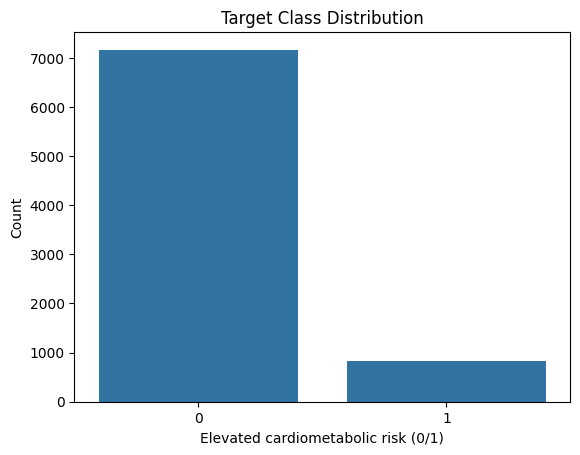

In [17]:
# Target distribution
ax = sns.countplot(data=df, x=TARGET)
ax.set_title("Target Class Distribution")
ax.set_xlabel("Elevated cardiometabolic risk (0/1)")
ax.set_ylabel("Count")
plt.show()

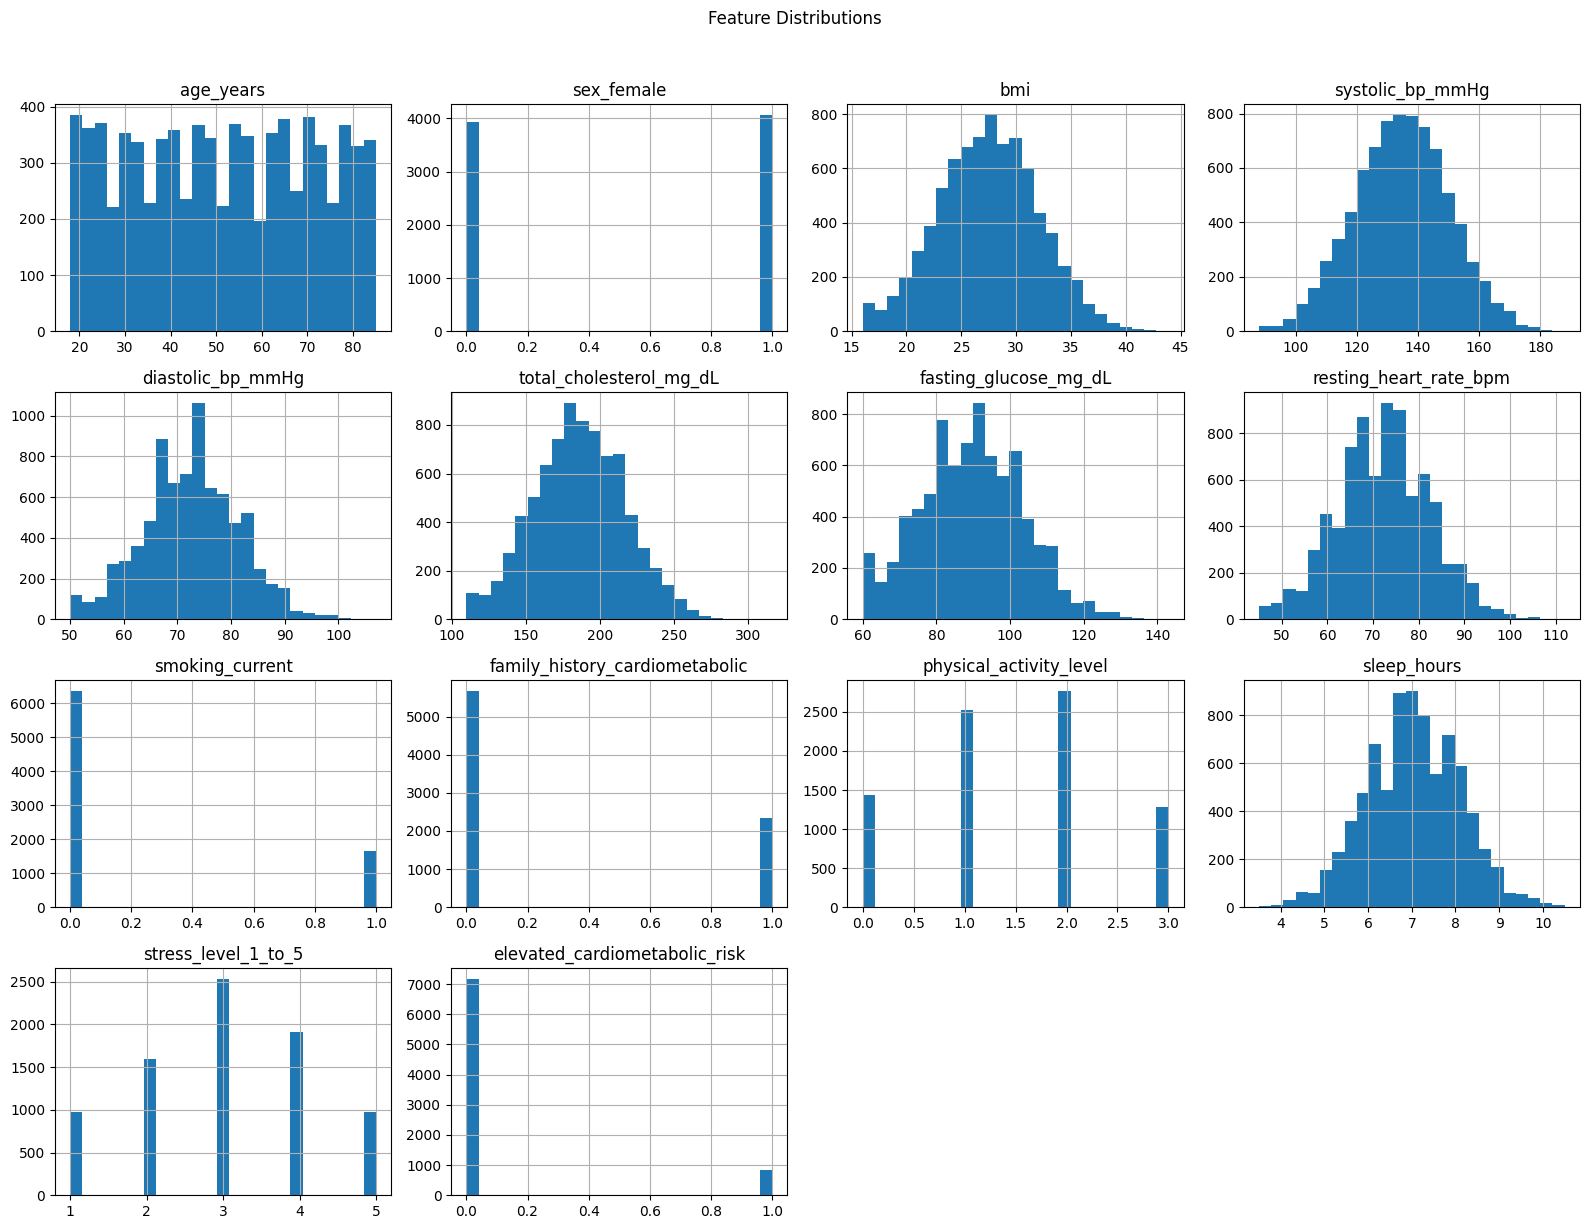

In [18]:
# Histograms for numeric features
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_cols].hist(figsize=(16, 12), bins=25, layout=(4, 4))
plt.suptitle("Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

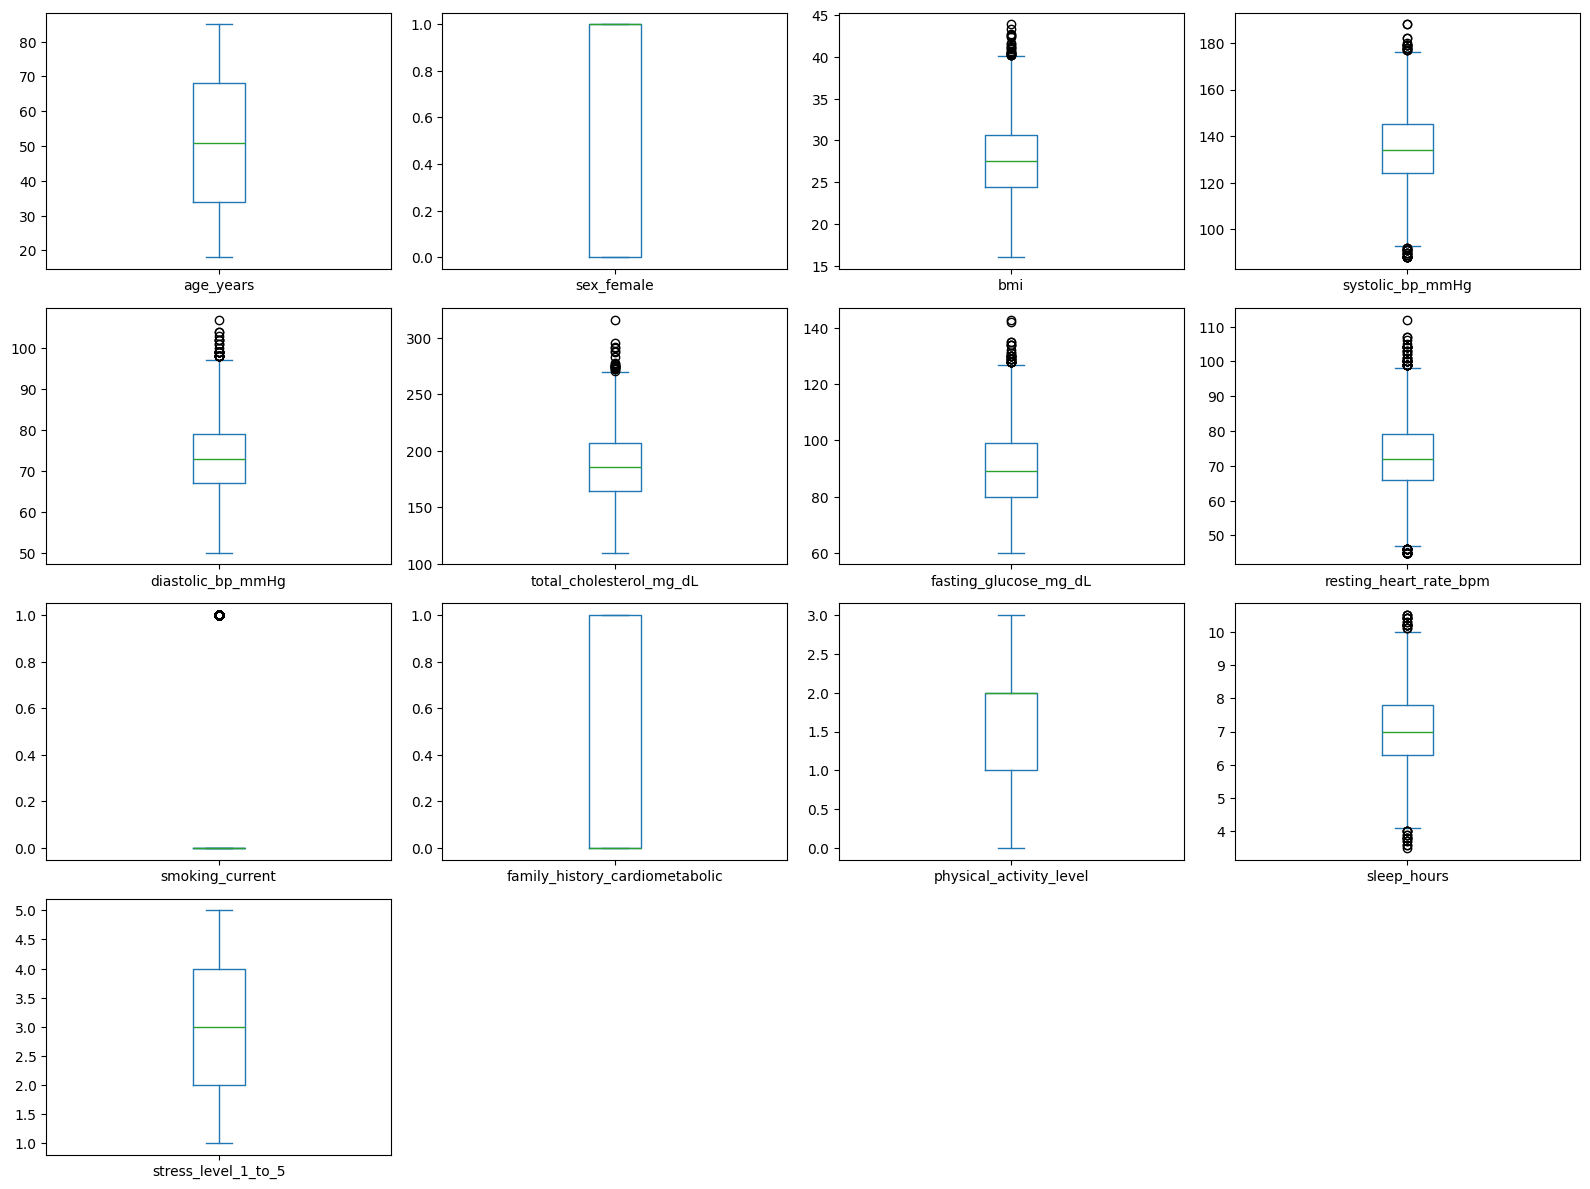

In [19]:
# Boxplots help visualize spread and possible outliers
feature_cols_before_engineering = [c for c in df.columns if c != TARGET]
df[feature_cols_before_engineering].plot(
    kind="box", subplots=True, layout=(4, 4),
    figsize=(16, 12), sharex=False, sharey=False
)
plt.tight_layout()
plt.show()

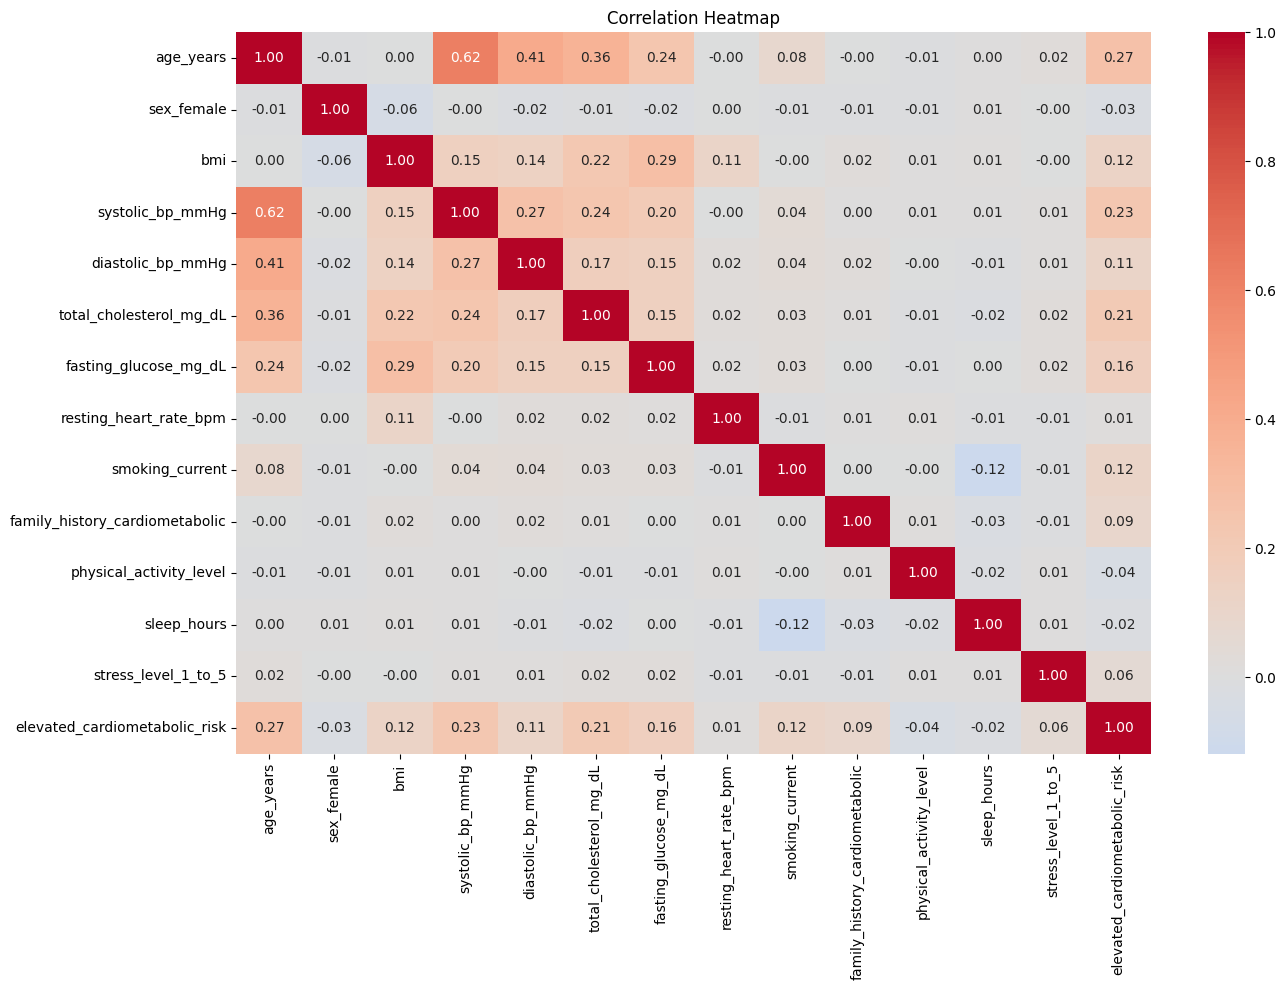

In [20]:
# Correlation heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

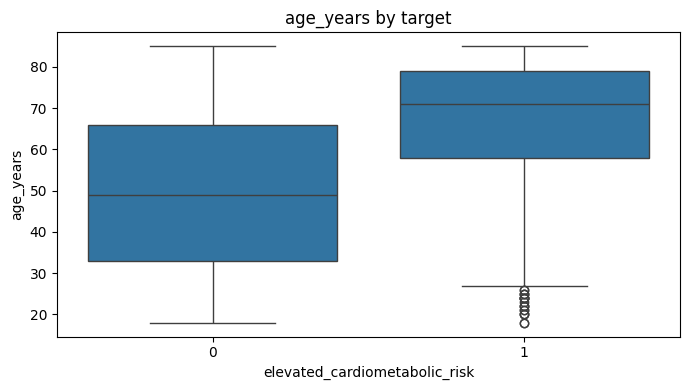

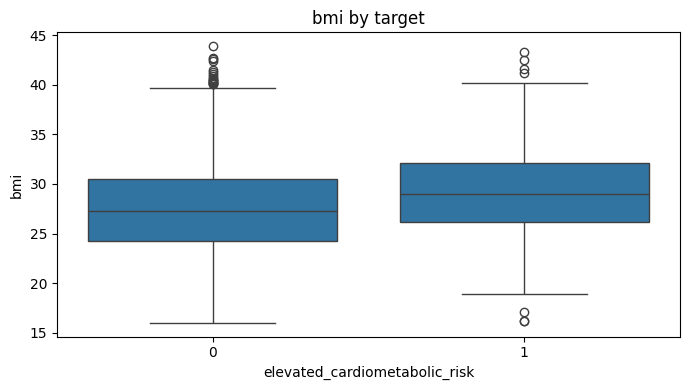

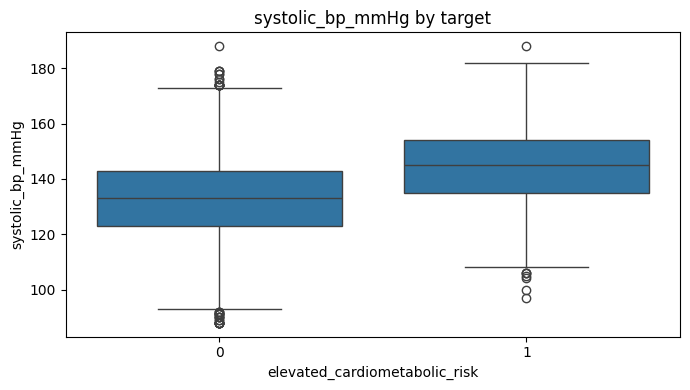

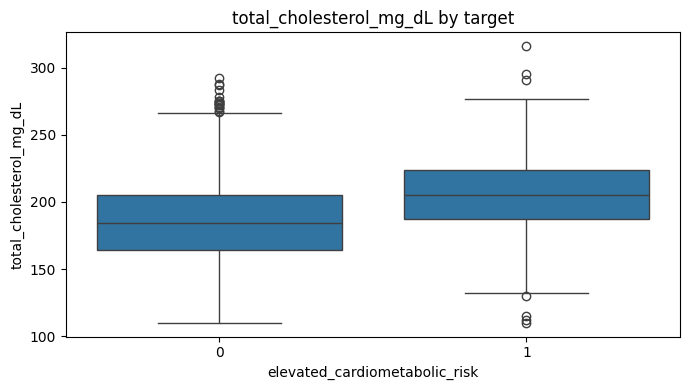

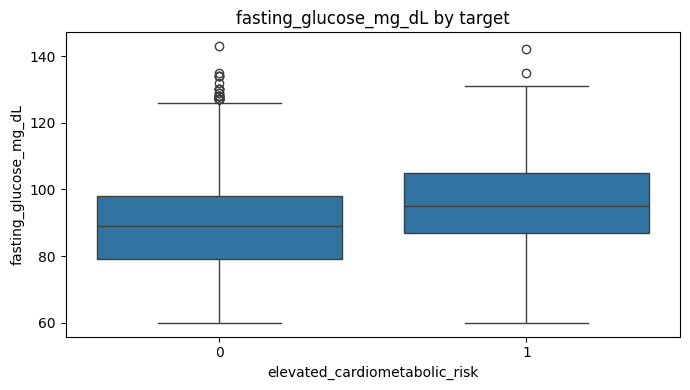

In [21]:
# Compare feature distributions by target
eda_features = [
    "age_years", "bmi", "systolic_bp_mmHg",
    "total_cholesterol_mg_dL", "fasting_glucose_mg_dL"
]
for feature in eda_features:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x=TARGET, y=feature)
    plt.title(f"{feature} by target")
    plt.tight_layout()
    plt.show()

In [22]:
def add_features(data):
    data = data.copy()
    data["pulse_pressure_mmHg"] = (
        data["systolic_bp_mmHg"] - data["diastolic_bp_mmHg"]
    )
    return data

df = add_features(df)

print("Shape after feature engineering:", df.shape)
display(df.head())

Shape after feature engineering: (8000, 15)


,age_years,sex_female,bmi,systolic_bp_mmHg,diastolic_bp_mmHg,total_cholesterol_mg_dL,fasting_glucose_mg_dL,resting_heart_rate_bpm,smoking_current,family_history_cardiometabolic,physical_activity_level,sleep_hours,stress_level_1_to_5,elevated_cardiometabolic_risk,pulse_pressure_mmHg
0,70,1,27.5,149,71,233,100,72,0,1,0,8.0,3,1,78
1,32,0,30.3,136,59,173,85,72,0,0,2,8.2,3,0,77
2,71,0,21.5,150,80,197,74,72,0,1,2,5.2,2,0,70
3,19,0,30.8,119,60,208,75,81,1,0,0,7.2,4,0,59
4,44,1,28.5,145,70,141,97,86,0,1,1,7.2,4,0,75


##  Separate features and target, then split

We use **70% training, 15% validation, and 15% test**. Stratification preserves the target proportions in each split. The test set is held back for final evaluation only.

In [ ]:
X = df.drop(columns=[TARGET])
y = df[TARGET].astype("int32")

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEED, stratify=y
)


X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.15 / 0.85,
    random_state=SEED,
    stratify=y_train_val
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

split_summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "rows": [len(y_train), len(y_val), len(y_test)],
    "positive_count": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "positive_rate": [y_train.mean(), y_val.mean(), y_test.mean()]
})
display(split_summary)

Train: (5600, 14) (5600,)
Validation: (1200, 14) (1200,)
Test: (1200, 14) (1200,)


,split,rows,positive_count,positive_rate
0,train,5600,585,0.104464
1,validation,1200,125,0.104167
2,test,1200,125,0.104167


## Preprocessing



In [24]:
numeric_features = X_train.columns.tolist()

preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Processed shapes:")
print("Train:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Test:", X_test_processed.shape)

Processed shapes:
Train: (5600, 14)
Validation: (1200, 14)
Test: (1200, 14)


##  ANN architecture

This is binary classification, so the output layer has one neuron with sigmoid activation. Hidden layers use ReLU.

In [25]:
n_features = X_train_processed.shape[1]

model = keras.Sequential([
    layers.Input(shape=(n_features,), name="input_features"),

    layers.Dense(
        32, activation="relu",
        kernel_regularizer=regularizers.l2(0.001),
        name="dense_32_l2"
    ),
    layers.Dropout(0.30, name="dropout_30"),

    layers.Dense(
        16, activation="relu",
        kernel_regularizer=regularizers.l2(0.001),
        name="dense_16_l2"
    ),
    layers.Dropout(0.20, name="dropout_20"),

    layers.Dense(1, activation="sigmoid", name="risk_probability")
], name="cardiometabolic_ann")

model.summary()

Model: "cardiometabolic_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_32_l2 (Dense)             │ (None, 32)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16_l2 (Dense)             │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ risk_probability (Dense)        │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,025 (4.00 KB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 0 (0.00 B)

## Compile the model

In [26]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc")
    ]
)

## Configure callbacks

- `ModelCheckpoint`: save the best model by validation loss.
- `EarlyStopping`: stop if validation loss does not improve, and restore best weights.
- `ReduceLROnPlateau`: reduce learning rate when validation loss plateaus.


In [27]:
ARTIFACT_DIR = "ann_artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

checkpoint_path = os.path.join(ARTIFACT_DIR, "best_ann.keras")
log_dir = os.path.join(ARTIFACT_DIR, "tensorboard_logs")
csv_log_path = os.path.join(ARTIFACT_DIR, "training_history.csv")

callbacks = [
    ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=12,
        min_delta=0.0005,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    TensorBoard(log_dir=log_dir),
    CSVLogger(csv_log_path, append=False)
]

## Train the ANN



In [28]:
EPOCHS = 100
BATCH_SIZE = 32

history = model.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    class_weight=None,  # optionally calculate class weights if justified
    verbose=1
)

Epoch 1/100
170/175 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8227 - auc: 0.5690 - loss: 0.4947
Epoch 1: val_loss improved from inf to 0.33617, saving model to ann_artifacts\best_ann.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.8244 - auc: 0.5709 - loss: 0.4921 - val_accuracy: 0.8958 - val_auc: 0.7554 - val_loss: 0.3362 - learning_rate: 0.0010
Epoch 2/100
171/175 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8993 - auc: 0.7282 - loss: 0.3435
Epoch 2: val_loss improved from 0.33617 to 0.32329, saving model to ann_artifacts\best_ann.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8992 - auc: 0.7288 - loss: 0.3435 - val_accuracy: 0.8958 - val_auc: 0.7839 - val_loss: 0.3233 - learning_rate: 0.0010
Epoch 3/100
166/175 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9012 - auc: 0.7618 - loss: 0.3284
Epoch 3: val_loss improved from 0.32329 to 0.31713, saving model to ann_artifacts\best_ann.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9010 - a

### Training curves

,accuracy,auc,loss,val_accuracy,val_auc,val_loss,learning_rate
38,0.897679,0.816111,0.274197,0.897500,0.801883,0.283893,0.0010
39,0.898750,0.817784,0.273985,0.897500,0.803200,0.283248,0.0010
40,0.900893,0.814343,0.274485,0.897500,0.802549,0.283452,0.0010
41,0.898214,0.815572,0.273810,0.897500,0.800380,0.283665,0.0005
42,0.896964,0.817138,0.274287,0.896667,0.799844,0.283766,0.0005


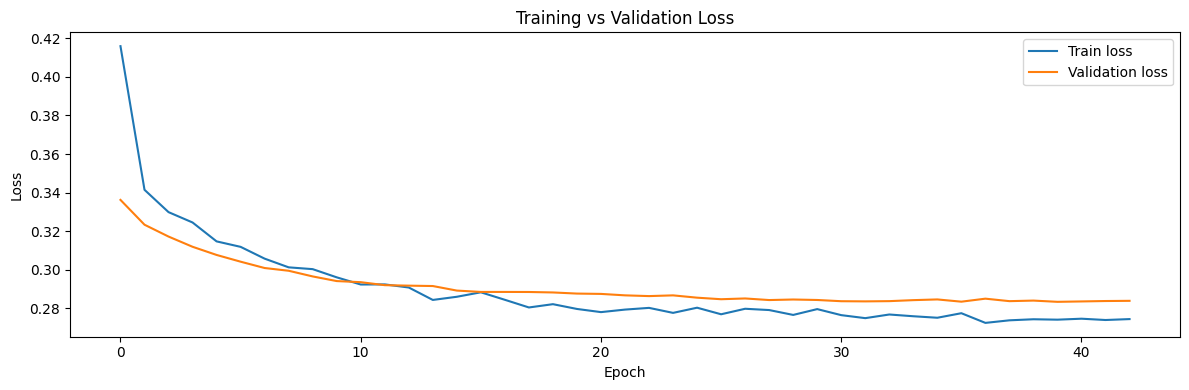

In [29]:
history_df = pd.DataFrame(history.history)
display(history_df.tail())

plt.figure(figsize=(12, 4))
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

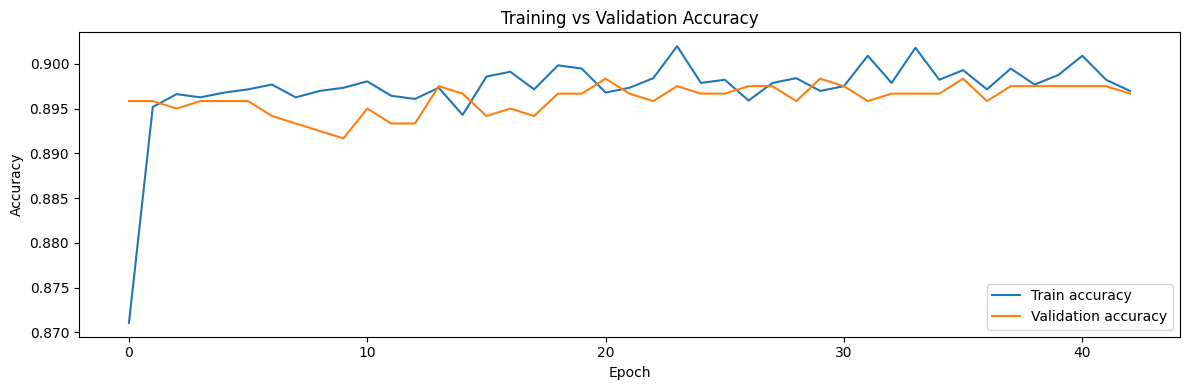

In [30]:
plt.figure(figsize=(12, 4))
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

## Load the best checkpoint and evaluate



In [31]:
best_model = keras.models.load_model(checkpoint_path)

test_results = best_model.evaluate(
    X_test_processed, y_test, verbose=0, return_dict=True
)
display(pd.Series(test_results, name="test_metrics"))

accuracy    0.905000
auc         0.808975
loss        0.277451
Name: test_metrics, dtype: float64

In [32]:
test_probabilities = best_model.predict(X_test_processed, verbose=0).ravel()
THRESHOLD = 0.5
test_predictions = (test_probabilities >= THRESHOLD).astype(int)

print(classification_report(
    y_test, test_predictions,
    target_names=["Not elevated (0)", "Elevated (1)"],
    zero_division=0
))

metrics_summary = pd.DataFrame([{
    "accuracy": accuracy_score(y_test, test_predictions),
    "precision": precision_score(y_test, test_predictions, zero_division=0),
    "recall": recall_score(y_test, test_predictions, zero_division=0),
    "f1": f1_score(y_test, test_predictions, zero_division=0),
    "roc_auc": roc_auc_score(y_test, test_probabilities)
}])
display(metrics_summary)

                  precision    recall  f1-score   support

Not elevated (0)       0.91      1.00      0.95      1075
    Elevated (1)       0.82      0.11      0.20       125

        accuracy                           0.91      1200
       macro avg       0.86      0.55      0.57      1200
    weighted avg       0.90      0.91      0.87      1200



,accuracy,precision,recall,f1,roc_auc
0,0.905,0.823529,0.112,0.197183,0.810575


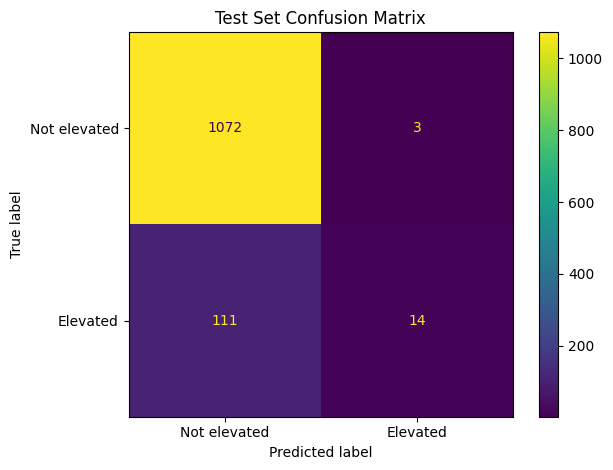

In [33]:
cm = confusion_matrix(y_test, test_predictions)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not elevated", "Elevated"]
).plot(values_format="d")
plt.title("Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

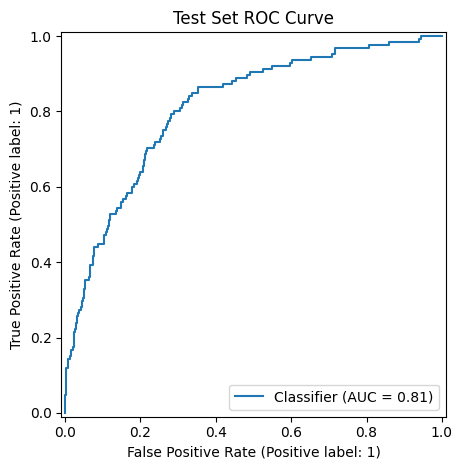

In [34]:
RocCurveDisplay.from_predictions(y_test, test_probabilities)
plt.title("Test Set ROC Curve")
plt.tight_layout()
plt.show()

## Save the model and preprocessing pipeline



In [36]:
import os

# Create directory
os.makedirs(ARTIFACT_DIR, exist_ok=True)

# Save model in Keras format
final_model_path = os.path.join(ARTIFACT_DIR, "final_ann.keras")

best_model.save(final_model_path)

print("Model saved successfully:", final_model_path)
print("File exists:", os.path.exists(final_model_path))

Model saved successfully: ann_artifacts\final_ann.keras
File exists: True


In [37]:
import tensorflow as tf

model = tf.keras.models.load_model(final_model_path)